# GEO population

Analysis dedicated to the geostationary orbit population, extracted from `18SDS_population.ipynb`.

Merges a TLE snapshot (file `tle_YYYYMMDD_YYYYMMDD.csv` written by `spacetrack_tle_snapshot.py`
in the folder set in `config.ini`, section `[tle_snapshot]`) with a SATCAT file
(`satcat_YYYYMMDD.csv` written by `spacetrack_satcat.py` in the folder set in section `[satcat]`).
Sub-satellite longitudes are computed with Orekit, whose data file is set in section `[orekit]`, key `data_path`.


In [1]:
from pathlib import Path
import configparser

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec

# Constants
MU = 398_600.4418       # Earth gravitational parameter, km³/s²
R_EARTH = 6_378.137     # Earth radius WGS84, km
SEC_PER_DAY = 86_400

TLE_SNAPSHOT = "tle_20260830_20260831.csv"
SATCAT       = "satcat_20260830.csv"

# Folders read from config.ini (same file as spacetrack_tle_snapshot.py and spacetrack_satcat.py)
config = configparser.ConfigParser()
if not config.read("config.ini", encoding="utf-8"):
    raise FileNotFoundError("config.ini not found next to the notebook")
TLE_FILE    = Path(config["tle_snapshot"]["output_dir"]).expanduser() / TLE_SNAPSHOT
SATCAT_FILE = Path(config["satcat"]["output_dir"]).expanduser() / SATCAT
OREKIT_DATA = Path(config.get("orekit", "data_path", fallback="orekit-data.zip")).expanduser()
for f in (TLE_FILE, SATCAT_FILE):
    if not f.exists():
        raise FileNotFoundError(f"File not found: {f} (see output_dir in config.ini)")

TOP_N       = 10          # countries shown individually
MIN_PCT     = 0.5         # below this % → merged into "Others"
OUTPUT      = Path("outputs/satcat_piechart.png")
OUTPUT_INC_VS_SMA_ALL = Path("outputs/population_inc_vs_sma_all.png")
OUTPUT_INC_VS_SMA_LEO = Path("outputs/population_inc_vs_sma_leo.png")
OUTPUT_INC_VS_SMA_GEO = Path("outputs/population_inc_vs_sma_geo.png")
OUTPUT_GEO_ACTIVE_BY_COUNTRY = Path("outputs/geo_active_satellites_by_country.png")
OUTPUT_GEO_ACTIVE_PIECHART = Path("outputs/geo_active_piechart_by_country.png")

TYPE_MAP = {
    "PAYLOAD":     ("Satellite",   "#2196F3", 3),
    "DEBRIS":      ("Debris",      "#FF5722", 2),
    "ROCKET BODY": ("Upper Stage", "#4CAF50", 4),
}

## Load the population

Create a dataframe merging the TLE and satcat files.


In [2]:
def parse_tle(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path, dtype={"norad_id": str})
    records = []
    for row in raw.itertuples(index=False):
        line1 = row.line1.strip()
        line2 = row.line2.strip()
        try:
            sat_id = int(row.norad_id)
        except ValueError:
            continue  # alpha-5 IDs not yet in SATCAT

        ecc     = float("0." + line2[26:33])
        inc     = float(line2[8:16])
        mn      = float(line2[52:63])
        n_rad_s = mn * 2 * math.pi / SEC_PER_DAY
        sma     = (MU / n_rad_s ** 2) ** (1 / 3)
 
        records.append({
            "NORAD_CAT_ID": sat_id,
            "sma": sma,
            "inc": inc,
            "per": sma * (1 - ecc) - R_EARTH,
            "apo": sma * (1 + ecc) - R_EARTH,
            "line1": line1,
            "line2": line2,
        })

    return pd.DataFrame(records)

def merge(satcat_path: Path, tle_df: pd.DataFrame) -> pd.DataFrame:
    satcat = pd.read_csv(satcat_path)
    df = satcat.merge(tle_df, on="NORAD_CAT_ID", how="inner")
    df = df[df["OBJECT_TYPE"].isin(TYPE_MAP)]   # drop UNKNOWN
    return df

tle_df = parse_tle(TLE_FILE)
population = merge(SATCAT_FILE, tle_df)
print(population.columns)

Index(['INTLDES', 'NORAD_CAT_ID', 'OBJECT_TYPE', 'SATNAME', 'COUNTRY',
       'LAUNCH', 'SITE', 'DECAY', 'PERIOD', 'INCLINATION', 'APOGEE', 'PERIGEE',
       'COMMENT', 'COMMENTCODE', 'RCSVALUE', 'RCS_SIZE', 'FILE', 'LAUNCH_YEAR',
       'LAUNCH_NUM', 'LAUNCH_PIECE', 'CURRENT', 'OBJECT_NAME', 'OBJECT_ID',
       'OBJECT_NUMBER', 'sma', 'inc', 'per', 'apo', 'line1', 'line2'],
      dtype='str')


Saved → outputs/population_inc_vs_sma_geo.png


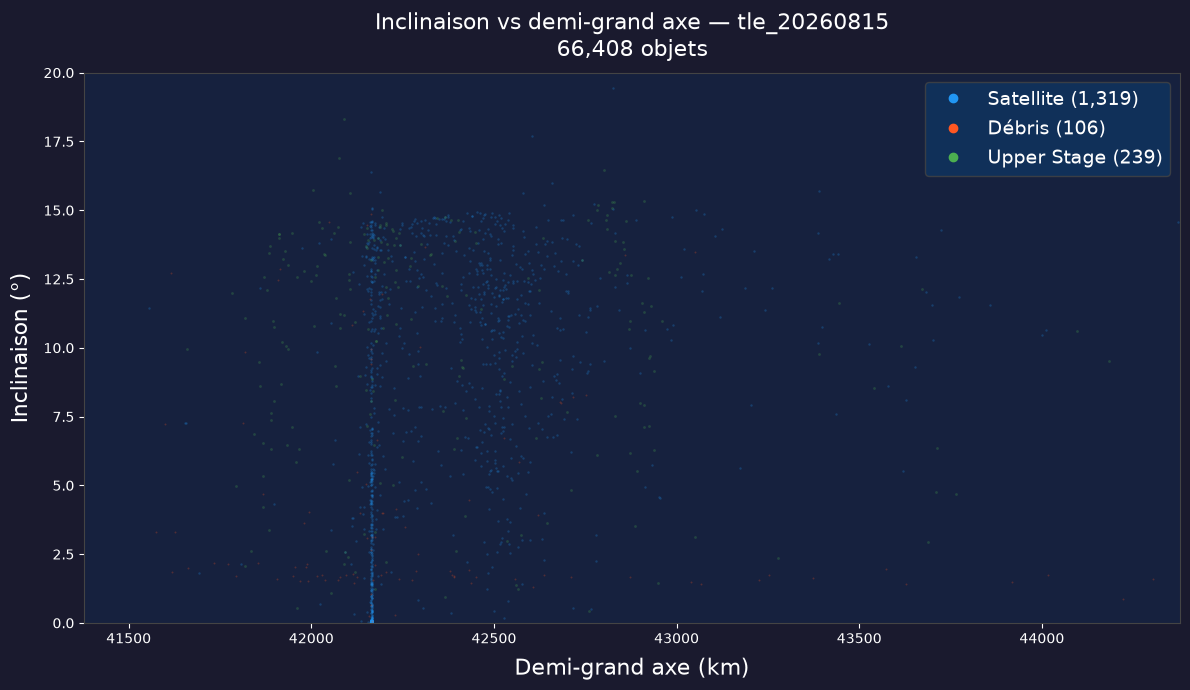

In [3]:
def leo_filter(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["apo"] < 2000) & (df["per"] < 2000)]

def geo_filter(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["apo"] < 42000) & (df["per"] > 35000 )]

def plot_inc_vs_sma(df: pd.DataFrame, output: Path, region: str) -> None:
    fig, ax = plt.subplots(figsize=(12, 7))
    fig.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#16213e")

    if region=='LEO':
        filtered_df = leo_filter(df)
    elif region=='GEO':
        filtered_df = geo_filter(df)
    else:
        filtered_df = df

    legend_handles = []

    for obj_type, (label, color, size) in TYPE_MAP.items():
        sub = filtered_df[filtered_df["OBJECT_TYPE"] == obj_type]
        ax.scatter(
            sub["sma"], sub["inc"],
            s=size, color=color, alpha=0.25,
            linewidths=0, rasterized=True,
        )
        legend_handles.append(
            mlines.Line2D([], [], color=color, marker="o", linestyle="None",
                          markersize=6, label=f"{label} ({len(sub):,})")
        )

    # Reference orbits
    #for name, alt in [("LEO 500 km", 500), ("GEO", 35_786)]:
    #    ax.axvline(R_EARTH + alt, color="white", linewidth=0.6,
    #               linestyle="--", alpha=0.4)
    #    ax.text(R_EARTH + alt + 60, 175, name,
    #            color="white", fontsize=7, alpha=0.6)

    ax.set_xlabel("Semi-major axis (km)", color="white", labelpad=8,fontsize=16)
    ax.set_ylabel("Inclination (°)", color="white", labelpad=8,fontsize=16)
    ax.set_title(
        f"Inclination vs semi-major axis — {TLE_FILE.stem}\n"
        f"{len(df):,} objects",
        color="white", fontsize=16, pad=12,
    )

    if region=='LEO':
        ax.set_xlim(R_EARTH, R_EARTH+2E3)
        ax.set_ylim(0, 160)
    elif region=='GEO':
        ax.set_xlim(R_EARTH+35E3, R_EARTH+38E3)
        ax.set_ylim(0, 20)
    else:
        ax.set_xlim(R_EARTH, R_EARTH+42E3)
        ax.set_ylim(0, 180)

    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_edgecolor("#444")

    ax.legend(
        handles=legend_handles,
        facecolor="#0f3460", edgecolor="#444",
        labelcolor="white", fontsize=14,
        loc="upper right",
    )

    fig.tight_layout()
    fig.savefig(output, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved → {output}")

plot_inc_vs_sma(population, OUTPUT_INC_VS_SMA_GEO, 'GEO')

## Population in GEO

In [4]:
population_geo = geo_filter(population)

print(f"GEO objects: {len(population_geo):,}")
print(population_geo.groupby('COUNTRY').size()
      .sort_values(ascending=False).head(20).to_string())

GEO objects: 1,664
COUNTRY
US      445
CIS     347
PRC     167
ITSO    116
JPN      68
SES      67
EUTE     61
IND      53
CA       28
FR       22
ESA      21
IM       19
BRAZ     19
UK       18
INDO     17
AB       15
AUS      13
SKOR     12
EUME     12
TURK      9


Saved → outputs/satcat_piechart.png


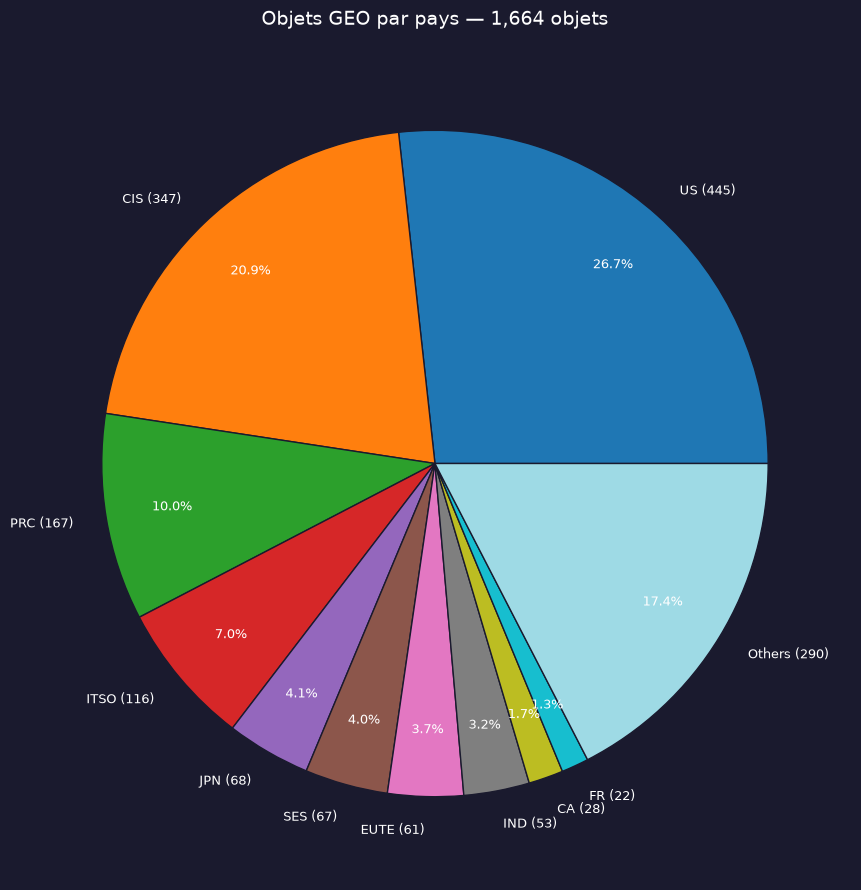

In [5]:
def plot_country_piechart(
    df: pd.DataFrame,
    output: Path,
    title: str,
    top_n: int = TOP_N,
    min_pct: float = MIN_PCT,
) -> None:
    counts = df["COUNTRY"].value_counts()
    pct    = counts / counts.sum() * 100

    keep = counts[pct >= min_pct].head(top_n).copy()
    others = counts.sum() - keep.sum()
    if others > 0:
        keep["Others"] = others

    colors = plt.cm.tab20(np.linspace(0, 1, len(keep)))

    fig, ax = plt.subplots(figsize=(9, 9))
    fig.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#1a1a2e")

    ax.pie(
        keep.values,
        labels=[f"{country} ({count:,})" for country, count in keep.items()],
        autopct=lambda p: f"{p:.1f}%" if p >= 1 else "",
        colors=colors,
        textprops={"color": "white", "fontsize": 9},
        pctdistance=0.8,
        wedgeprops={"edgecolor": "#1a1a2e", "linewidth": 1},
    )
    ax.set_title(title, color="white", fontsize=14, pad=16)

    fig.tight_layout()
    fig.savefig(output, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved → {output}")

plot_country_piechart(
    population_geo, OUTPUT,
    f"GEO objects by country — {len(population_geo):,} objects",
)

Saved → outputs/geo_active_satellites_by_country.png


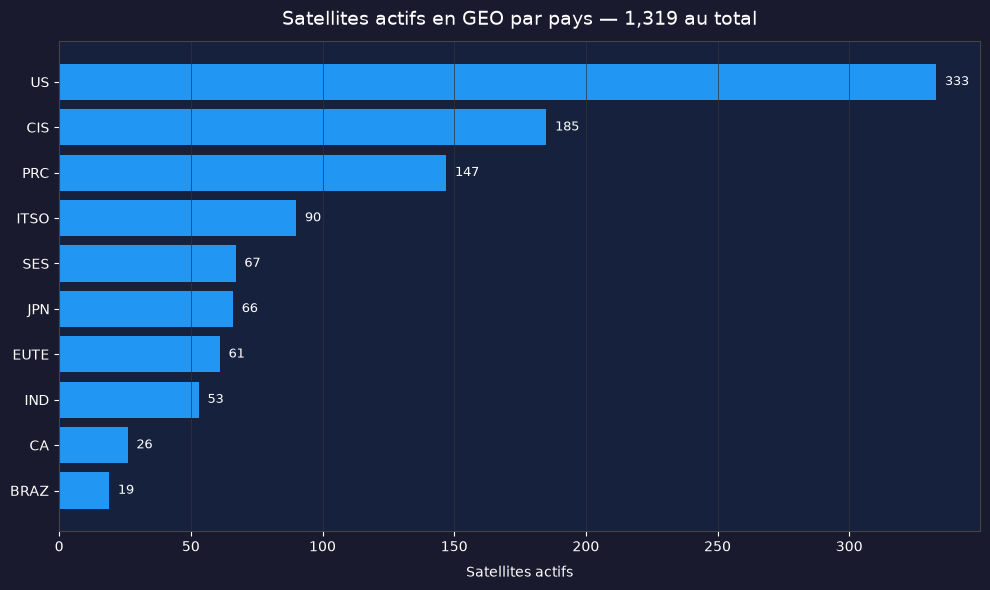

In [6]:
def plot_active_by_country(
    df: pd.DataFrame,
    output: Path,
    top_n: int = TOP_N,
) -> None:
    active = df[(df["OBJECT_TYPE"] == "PAYLOAD") & (df["CURRENT"] == "Y")]
    counts = active["COUNTRY"].value_counts().head(top_n)

    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#16213e")

    ax.barh(counts.index[::-1], counts.values[::-1], color="#2196F3")
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v + counts.values.max() * 0.01, i, f"{v:,}",
                 color="white", va="center", fontsize=9)

    ax.set_xlabel("Active satellites", color="white", labelpad=8)
    ax.set_title(
        f"Active GEO satellites by country — {len(active):,} in total",
        color="white", fontsize=14, pad=12,
    )
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_edgecolor("#444")
    ax.grid(axis="x", color="#333", linewidth=0.5)

    fig.tight_layout()
    fig.savefig(output, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved → {output}")

plot_active_by_country(population_geo, OUTPUT_GEO_ACTIVE_BY_COUNTRY)

In [8]:
import orekit
vm = orekit.initVM()                      # start the JVM — must be first

from orekit.pyhelpers import setup_orekit_curdir
if not OREKIT_DATA.exists():
    raise FileNotFoundError(f"Orekit data not found: {OREKIT_DATA} (see [orekit] data_path in config.ini)")
setup_orekit_curdir(str(OREKIT_DATA))
 
from org.orekit.bodies import OneAxisEllipsoid
from org.orekit.frames import FramesFactory
from org.orekit.propagation.analytical.tle import TLE, TLEPropagator
from org.orekit.time import AbsoluteDate, TimeScalesFactory
from org.orekit.utils import Constants, IERSConventions

def build_earth() -> tuple[OneAxisEllipsoid, "Frame"]:
    """WGS84 ellipsoid attached to the ITRF frame."""
    itrf = FramesFactory.getITRF(IERSConventions.IERS_2010, True)
    earth = OneAxisEllipsoid(
        Constants.WGS84_EARTH_EQUATORIAL_RADIUS,
        Constants.WGS84_EARTH_FLATTENING,
        itrf,
    )
    return earth, itrf

def compute_longitude(
    line1: str,
    line2: str,
    earth: OneAxisEllipsoid,
    itrf,
    date: AbsoluteDate | None = None,
) -> float | None:
    """Sub-satellite longitude (deg, [-180, 180]) via Orekit's SGP4.
 
    If `date` is None, the TLE's own epoch is used.
    """
    try:
        tle        = TLE(line1, line2)
        propagator = TLEPropagator.selectExtrapolator(tle)
        t          = date if date is not None else tle.getDate()
 
        pos = propagator.propagate(t).getPVCoordinates(itrf).getPosition()
        gp  = earth.transform(pos, itrf, t)
        return math.degrees(gp.getLongitude())   # Orekit returns [-pi, pi]
    except Exception as exc:
        print(f"  [skip] {line1[2:7]}: {exc}")
        return None

In [9]:
def plot_geo(df: pd.DataFrame, output: Path) -> None:
    fig = plt.figure(figsize=(16, 9))
    fig.patch.set_facecolor("#1a1a2e")
    gs = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1, 1.3],
                           hspace=0.32, wspace=0.18)
 
    ax_scatter = fig.add_subplot(gs[0, :])
    ax_hist    = fig.add_subplot(gs[1, 0])
    ax_polar   = fig.add_subplot(gs[1, 1], projection="polar")
 
    # ── 1. Longitude vs inclination ──────────────────────────────────────────
    ax_scatter.set_facecolor("#16213e")
    for obj_type, (label, color, size) in TYPE_STYLE.items():
        sub = df[df["OBJECT_TYPE"] == obj_type]
        ax_scatter.scatter(sub["lon"], sub["inc"], s=size, color=color,
                           alpha=0.65, linewidths=0,
                           label=f"{label} ({len(sub):,})")
 
    ax_scatter.set_xlim(-180, 180)
    ax_scatter.set_xticks(range(-180, 181, 30))
    ax_scatter.set_xlabel("Longitude (°E)", color="white")
    ax_scatter.set_ylabel("Inclination (°)", color="white")
    ax_scatter.set_title("Geostationary arc — longitude vs inclination",
                         color="white", fontsize=11)
    ax_scatter.legend(facecolor="#0f3460", edgecolor="#444",
                      labelcolor="white", fontsize=8, loc="upper right")
 
    # ── 2. Density by longitude ──────────────────────────────────────────────
    ax_hist.set_facecolor("#16213e")
    bins = np.arange(-180, 180 + LON_BIN_DEG, LON_BIN_DEG)
    ax_hist.hist(
        [df[df["OBJECT_TYPE"] == t]["lon"] for t in TYPE_STYLE],
        bins=bins, stacked=True,
        color=[TYPE_STYLE[t][1] for t in TYPE_STYLE],
        label=[TYPE_STYLE[t][0] for t in TYPE_STYLE],
    )
    ax_hist.set_xlim(-180, 180)
    ax_hist.set_xticks(range(-180, 181, 60))
    ax_hist.set_xlabel("Longitude (°E)", color="white")
    ax_hist.set_ylabel(f"Objects / {LON_BIN_DEG:g}°", color="white")
    ax_hist.set_title("Density along the arc", color="white", fontsize=11)
    ax_hist.legend(facecolor="#0f3460", edgecolor="#444",
                   labelcolor="white", fontsize=8)
 
    # ── 3. Polar view of the GEO ring ────────────────────────────────────────
    ax_polar.set_facecolor("#16213e")
    radius = {"PAYLOAD": 1.0, "ROCKET BODY": 1.12, "DEBRIS": 1.24}
    for obj_type, (label, color, size) in TYPE_STYLE.items():
        sub   = df[df["OBJECT_TYPE"] == obj_type]
        theta = np.radians(sub["lon"].values)
        r     = np.full(len(sub), radius[obj_type])
        ax_polar.scatter(theta, r, s=size * 0.5, color=color, alpha=0.7, linewidths=0)
 
    ax_polar.set_theta_zero_location("N")
    ax_polar.set_theta_direction(1)
    ax_polar.set_rlim(0, 1.45)
    ax_polar.set_yticks([])
    ax_polar.set_xticks(np.radians(range(0, 360, 30)))
    ax_polar.set_xticklabels([f"{(l + 180) % 360 - 180:.0f}°"
                              for l in range(0, 360, 30)],
                             color="white", fontsize=7)
    ax_polar.grid(color="#444", linewidth=0.5)
    ax_polar.set_title("Polar view of the GEO belt", color="white",
                       fontsize=11, pad=14)
 
    for ax in (ax_scatter, ax_hist):
        ax.tick_params(colors="white", labelsize=8)
        ax.grid(color="#333", linewidth=0.5)
        for spine in ax.spines.values():
            spine.set_edgecolor("#444")
    ax_polar.tick_params(colors="white")
 
    fig.suptitle(
        f"Geostationary arc population — {len(df):,} objects",
        color="white", fontsize=13, y=0.96,
    )
    fig.savefig(output, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved → {output}")


      norad             name         lon      inc OBJECT_TYPE
0       634  SYNCOM 2 (A 26)   64.988691  29.8571     PAYLOAD
1       858         SYNCOM 3  105.926173   7.1046     PAYLOAD
2      1317    INTELSAT 1-F1 -140.276630   7.2955     PAYLOAD
3      2608            ATS 1  155.662022   5.1158     PAYLOAD
4      2639    INTELSAT 2-F2  -77.281777   3.3992     PAYLOAD
...     ...              ...         ...      ...         ...
1659  68893      VIASAT 3-F3  158.575005   0.0136     PAYLOAD
1660  69235           TJS-24   90.307537   0.1569     PAYLOAD
1661  69474           TJS-25  120.233132   5.9171     PAYLOAD
1662  69674          TJS-26A  107.645746   6.9048     PAYLOAD
1663  69728     SIRIUS XM-11 -120.472302   0.0447     PAYLOAD

[1664 rows x 5 columns]
Saved → outputs/geo_belt.png


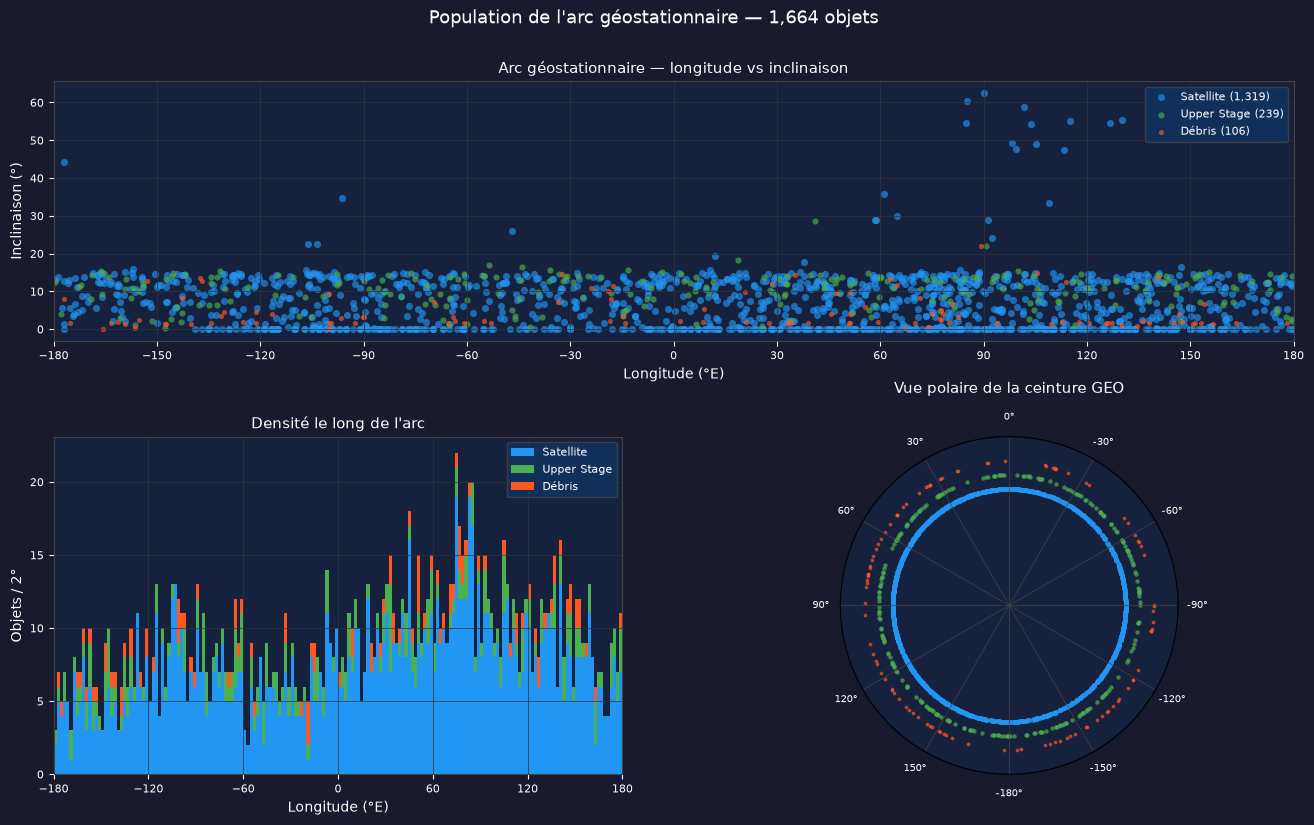

In [15]:
earth, itrf = build_earth()

REFERENCE_DATE = (2026, 8, 30, 0, 0, 0.0)   # close to the TLE snapshot epoch
LON_BIN_DEG = 2.0   # histogram bin width
TYPE_STYLE = {
    "PAYLOAD":     ("Satellite",   "#2196F3", 26),
    "ROCKET BODY": ("Upper Stage", "#4CAF50", 20),
    "DEBRIS":      ("Debris",      "#FF5722", 14),
}

utc  = TimeScalesFactory.getUTC()
date = AbsoluteDate(*REFERENCE_DATE, utc)

population_geo.to_csv('geo.csv', index=False)

pop = []
for idx in population_geo.index:
    norad = population_geo.loc[idx]['NORAD_CAT_ID']
    name = population_geo.loc[idx]['SATNAME']
    country = population_geo.loc[idx]['COUNTRY']
    line1 = population_geo.loc[idx]['line1']
    line2 = population_geo.loc[idx]['line2']
    longitude = compute_longitude(line1, line2, earth, itrf, date)
    inc = population_geo.loc[idx]['inc']
    object_type = population_geo.loc[idx]['OBJECT_TYPE']
    pop.append([norad, name, longitude, inc, object_type])
pop = pd.DataFrame(pop, columns=['norad','name','lon','inc','OBJECT_TYPE'])
print(pop)
plot_geo(pop, 'outputs/geo_belt.png')

# GEO region by country

In [11]:
# ── Per-country settings ─────────────────────────────────────────────────────
COUNTRIES_HIGHLIGHT = {
    'PRC': ('China',         '#FF4444'),   # red
    'US':  ('United States', '#4499FF'),   # blue
}
OUTPUT_GEO_BY_COUNTRY = Path('outputs/geo_by_country.png')

# ── Filter: active payloads in GEO ─────────────────────────────────────────
# CURRENT == 'Y' flags an operational satellite in the SATCAT
active_geo = population_geo[
    (population_geo['OBJECT_TYPE'] == 'PAYLOAD') &
    (population_geo['CURRENT'] == 'Y')
].copy()

print(f'Active GEO payloads: {len(active_geo)}')
print(active_geo.groupby('COUNTRY').size()
      .sort_values(ascending=False).head(20).to_string())

Active GEO payloads: 1319
COUNTRY
US      333
CIS     185
PRC     147
ITSO     90
SES      67
JPN      66
EUTE     61
IND      53
CA       26
IM       19
BRAZ     19
UK       18
INDO     17
AB       15
ESA      14
AUS      13
FR       13
SKOR     12
SPN       9
TURK      9


Saved → outputs/geo_active_piechart_by_country.png


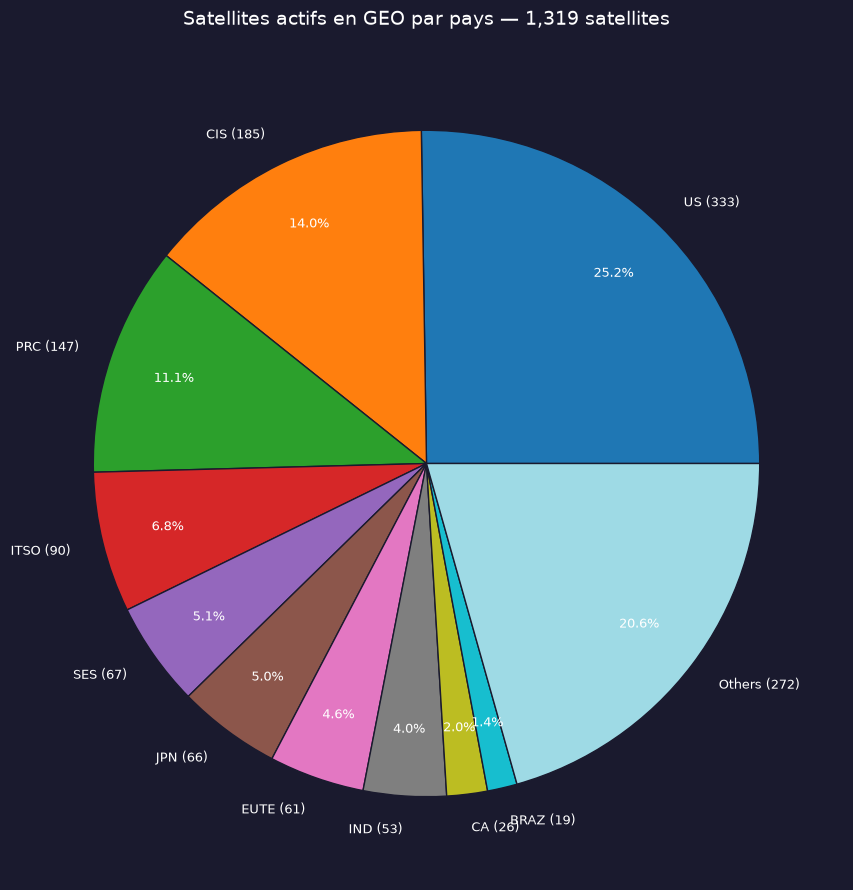

In [12]:
plot_country_piechart(
    active_geo, OUTPUT_GEO_ACTIVE_PIECHART,
    f"Active GEO satellites by country — {len(active_geo):,} satellites",
)

In [13]:
# Compute longitudes for all active GEO payloads (single pass)
records = []
for idx in active_geo.index:
    row = active_geo.loc[idx]
    lon = compute_longitude(row['line1'], row['line2'], earth, itrf, date)
    if lon is not None:
        records.append({
            'norad':   row['NORAD_CAT_ID'],
            'name':    row['SATNAME'],
            'country': row['COUNTRY'],
            'lon':     lon,
            'inc':     float(row['inc']),
        })

all_active_geo = pd.DataFrame(records)
print(f'{len(all_active_geo)} longitudes computed')

1319 longitudes computed


Saved → outputs/geo_by_country.png


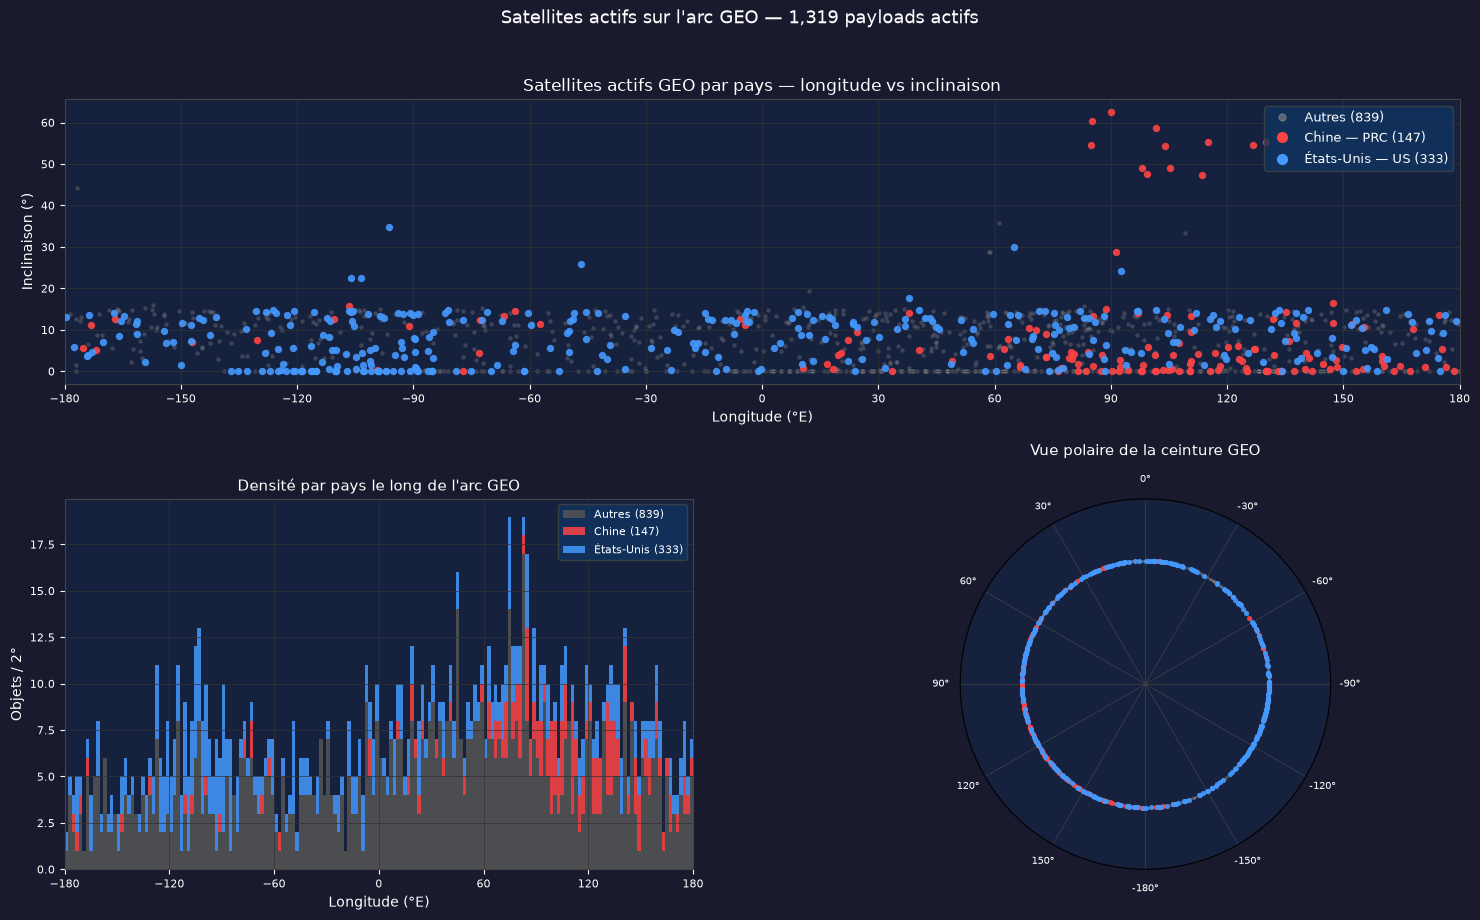

In [14]:
def plot_geo_by_country(
    df: pd.DataFrame,
    countries: dict,
    output: Path,
    lon_bin_deg: float = 2.0,
) -> None:
    """
    Plot the GEO belt, colouring satellites by country.

    df       : DataFrame with columns lon, inc, country, name, norad
    countries: {code: (label, colour)} of the countries to highlight
    """
    fig = plt.figure(figsize=(18, 10))
    fig.patch.set_facecolor('#1a1a2e')
    gs = gridspec.GridSpec(2, 2, figure=fig,
                           height_ratios=[1, 1.3],
                           hspace=0.35, wspace=0.22)

    ax_scatter = fig.add_subplot(gs[0, :])
    ax_hist    = fig.add_subplot(gs[1, 0])
    ax_polar   = fig.add_subplot(gs[1, 1], projection='polar')

    highlighted = set(countries.keys())
    others = df[~df['country'].isin(highlighted)]

    # ── 1. Longitude vs inclination ──────────────────────────────────────────
    ax_scatter.set_facecolor('#16213e')

    ax_scatter.scatter(
        others['lon'], others['inc'],
        s=10, color='#888888', alpha=0.35, linewidths=0,
    )
    legend_handles = [
        mlines.Line2D([], [], color='#888888', marker='o', linestyle='None',
                      markersize=5, alpha=0.6,
                      label=f'Others ({len(others):,})')
    ]
    for code, (label, color) in countries.items():
        sub = df[df['country'] == code]
        ax_scatter.scatter(sub['lon'], sub['inc'],
                           s=28, color=color, alpha=0.90,
                           linewidths=0, zorder=4)
        legend_handles.append(
            mlines.Line2D([], [], color=color, marker='o', linestyle='None',
                          markersize=7,
                          label=f'{label} — {code} ({len(sub):,})')
        )

    ax_scatter.set_xlim(-180, 180)
    ax_scatter.set_xticks(range(-180, 181, 30))
    ax_scatter.set_xlabel('Longitude (°E)', color='white')
    ax_scatter.set_ylabel('Inclination (°)', color='white')
    ax_scatter.set_title(
        'Active GEO satellites by country — longitude vs inclination',
        color='white', fontsize=12)
    ax_scatter.legend(handles=legend_handles,
                      facecolor='#0f3460', edgecolor='#444',
                      labelcolor='white', fontsize=9, loc='upper right')

    # ── 2. Density histogram by country ──────────────────────────────────────
    ax_hist.set_facecolor('#16213e')
    bins = np.arange(-180, 181, lon_bin_deg)

    series = [others['lon'].values]
    colors = ['#555555']
    labels = [f'Others ({len(others):,})']
    for code, (label, color) in countries.items():
        sub = df[df['country'] == code]
        series.append(sub['lon'].values)
        colors.append(color)
        labels.append(f'{label} ({len(sub):,})')

    ax_hist.hist(series, bins=bins, stacked=True,
                 color=colors, label=labels, alpha=0.85)
    ax_hist.set_xlim(-180, 180)
    ax_hist.set_xticks(range(-180, 181, 60))
    ax_hist.set_xlabel('Longitude (°E)', color='white')
    ax_hist.set_ylabel(f'Objects / {lon_bin_deg:g}°', color='white')
    ax_hist.set_title('Density by country along the GEO arc',
                       color='white', fontsize=11)
    ax_hist.legend(facecolor='#0f3460', edgecolor='#444',
                   labelcolor='white', fontsize=8)

    # ── 3. Polar view ────────────────────────────────────────────────────────
    ax_polar.set_facecolor('#16213e')
    theta_o = np.radians(others['lon'].values)
    ax_polar.scatter(theta_o, np.ones(len(others)),
                     s=5, color='#888888', alpha=0.30, linewidths=0)
    for code, (label, color) in countries.items():
        sub = df[df['country'] == code]
        theta = np.radians(sub['lon'].values)
        ax_polar.scatter(theta, np.ones(len(sub)),
                         s=14, color=color, alpha=0.90,
                         linewidths=0, zorder=4)

    ax_polar.set_theta_zero_location('N')
    ax_polar.set_theta_direction(1)
    ax_polar.set_rlim(0, 1.5)
    ax_polar.set_yticks([])
    ax_polar.set_xticks(np.radians(range(0, 360, 30)))
    ax_polar.set_xticklabels(
        [f"{(lon + 180) % 360 - 180:.0f}°" for lon in range(0, 360, 30)],
        color='white', fontsize=7)
    ax_polar.grid(color='#444', linewidth=0.5)
    ax_polar.set_title('Polar view of the GEO belt',
                        color='white', fontsize=11, pad=14)

    for ax in (ax_scatter, ax_hist):
        ax.tick_params(colors='white', labelsize=8)
        ax.grid(color='#333', linewidth=0.5)
        for spine in ax.spines.values():
            spine.set_edgecolor('#444')
    ax_polar.tick_params(colors='white')

    fig.suptitle(
        f"Active satellites on the GEO arc — {len(df):,} active payloads",
        color='white', fontsize=13, y=0.97,
    )
    fig.savefig(output, dpi=150, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    print(f'Saved → {output}')


plot_geo_by_country(all_active_geo, COUNTRIES_HIGHLIGHT, OUTPUT_GEO_BY_COUNTRY)
